**Checkpointing added.** Results and weights are saved to Google Drive after every epoch / experiment.
If the session crashes: reconnect, then **Runtime -> Run all** (or run cells 1 to the end). Finished experiments are skipped
instantly; the interrupted one resumes from its last completed epoch. To force a re-run of one experiment, delete its folder
in `attention_resnet50_results/checkpoints/`.

**Also fixed/added:** missing `find_all_attention_components` (feature-map cell crashed), channel-attention weights lookup, CBAM module + `CBAM P3` experiment, channel-attention Grad-CAM + self-attention response in the qualitative grid, extended Input|Baseline|SE|ECA|CBAM|Self-Attention figure, and a before/after feature-dimension table. SE is not run separately (identical to `Channel P3`). Duplicate trainings are reused (order and kernel-7 runs, P3-only/P4-only).


In [8]:
!pip -q install tensorflow-datasets

import os
import sys
import time
import json
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [42]:
SEED = 42
IMG_SIZE = 224
NUM_CLASSES = 5
BATCH_SIZE = 32


INITIAL_EPOCHS = 3
FINETUNE_EPOCHS = 2

INITIAL_LR = 1e-3
FINETUNE_LR = 1e-5
DROPOUT = 0.3

RUN_MULTISTAGE = True
RUN_ORDER = True
RUN_KERNEL = True
RUN_ECA = True
RUN_CBAM = True
RUN_P2P3P4 = False   # optional extended multi-stage experiment (P2+P3+P4)

INFERENCE_BATCHES = 10

CLASS_NAMES = ds_info.features["label"].names

# Results + checkpoints live on Google Drive so they survive a crashed/reset runtime.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/attention_resnet50_results"
except ImportError:                      # not on Colab
    OUTPUT_DIR = "./attention_resnet50_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Saving everything to:", OUTPUT_DIR)

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print("Configuration loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving everything to: /content/drive/MyDrive/attention_resnet50_results
Configuration loaded.


In [43]:
!pip -q install -U importlib-resources tensorflow-datasets seaborn tensorflow
(ds_full, ds_info) = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)

raw_images = []
raw_labels = []

for image, label in tfds.as_numpy(ds_full):
    raw_images.append(image)
    raw_labels.append(label)

raw_images = np.array(raw_images, dtype=object)
raw_labels = np.array(raw_labels)

print("Total images:", len(raw_images))
print("Classes:", ds_info.features["label"].names)
print("Class counts:")
print(pd.Series(raw_labels).value_counts().sort_index())


Total images: 3670
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Class counts:
0    898
1    633
2    799
3    699
4    641
Name: count, dtype: int64


In [44]:
rng = np.random.default_rng(SEED)

indices = np.arange(len(raw_labels))

train_idx = []
val_idx = []
test_idx = []

for class_id in range(NUM_CLASSES):

    class_indices = indices[raw_labels == class_id].copy()
    rng.shuffle(class_indices)

    n = len(class_indices)

    n_train = int(0.70 * n)
    n_val = int(0.15 * n)

    train_idx.extend(class_indices[:n_train])
    val_idx.extend(class_indices[n_train:n_train + n_val])
    test_idx.extend(class_indices[n_train + n_val:])

# Shuffle each split
rng.shuffle(train_idx)
rng.shuffle(val_idx)
rng.shuffle(test_idx)

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

print("Train:", len(train_idx), f"({len(train_idx)/len(indices):.1%})")
print("Validation:", len(val_idx), f"({len(val_idx)/len(indices):.1%})")
print("Test:", len(test_idx), f"({len(test_idx)/len(indices):.1%})")

# Check class distribution
print("\nClass distribution:")

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(name, np.bincount(
        raw_labels[idx],
        minlength=NUM_CLASSES
    ))

Train: 2567 (69.9%)
Validation: 547 (14.9%)
Test: 556 (15.1%)

Class distribution:
Train [628 443 559 489 448]
Validation [134  94 119 104  96]
Test [136  96 121 106  97]


In [45]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10),
], name="augmentation")


def preprocess_image(image, label, training=False):
    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    image = tf.cast(image, tf.float32)
    if training:
        image = augmentation(image, training=True)

    # ResNet50 ImageNet preprocessing
    image = preprocess_input(image)

    # One-hot encode the 5 classes
    label = tf.one_hot(
        tf.cast(label, tf.int32),
        NUM_CLASSES
    )

    return image, label


def make_dataset(indices, training=False):

    indices = np.asarray(indices)

    def generator():
        for i in indices:
            yield (
                raw_images[int(i)].astype(np.uint8),
                np.int32(raw_labels[int(i)])
            )

    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(
                shape=(None, None, 3),
                dtype=tf.uint8
            ),
            tf.TensorSpec(
                shape=(),
                dtype=tf.int32
            )
        )
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(indices),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda x, y: preprocess_image(
            x,
            y,
            training=training
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

train_ds = make_dataset(
    train_idx,
    training=True
)

val_ds = make_dataset(
    val_idx,
    training=False
)

test_ds = make_dataset(
    test_idx,
    training=False
)

print("Datasets created successfully.")
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Datasets created successfully.
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 5)


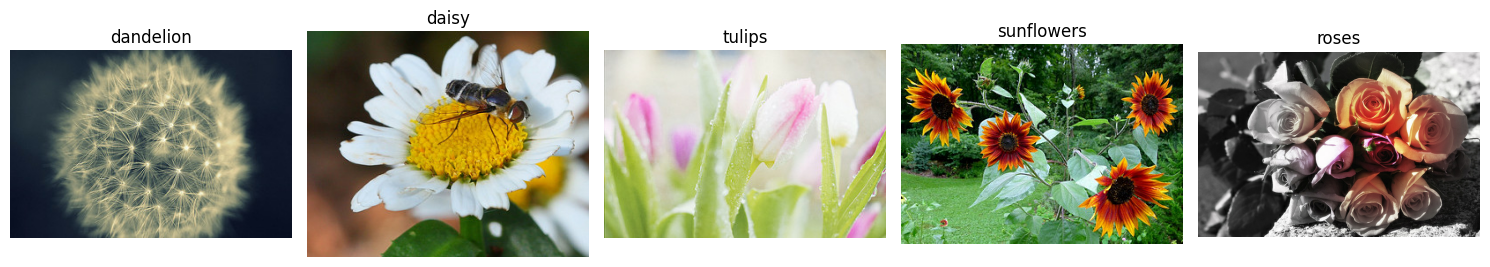

In [46]:
plt.figure(figsize=(15, 3))

for c in range(NUM_CLASSES):
    idx = next(i for i in test_idx if raw_labels[i] == c)
    image = raw_images[idx]

    plt.subplot(1, NUM_CLASSES, c + 1)
    plt.imshow(image)
    plt.title(CLASS_NAMES[c])
    plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sample_inputs.png"), dpi=160)
plt.show()


In [47]:
class ChannelAttention(layers.Layer):
    def __init__(self, channels, reduction=16, name="channel_attention", **kwargs):
        super().__init__(name=name, **kwargs)
        hidden = max(channels // reduction, 1)
        self.gap = layers.GlobalAveragePooling2D(keepdims=True)
        self.fc1 = layers.Conv2D(hidden, 1, activation="relu", use_bias=True)
        self.fc2 = layers.Conv2D(channels, 1, activation="sigmoid", use_bias=True)
        self.last_attention = None

    def call(self, x):
        z = self.gap(x)
        a = self.fc2(self.fc1(z))
        self.last_attention = a
        return x * a


class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, name="spatial_attention", **kwargs):
        super().__init__(name=name, **kwargs)
        self.conv = layers.Conv2D(
            1, kernel_size, padding="same", activation="sigmoid",
            use_bias=False
        )
        self.last_attention = None

    def call(self, x):
        avg_map = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_map = tf.reduce_max(x, axis=-1, keepdims=True)
        pooled = tf.concat([avg_map, max_map], axis=-1)
        a = self.conv(pooled)
        self.last_attention = a
        return x * a


class ChannelSpatialAttention(layers.Layer):
    def __init__(self, channels, reduction=16, kernel_size=7,
                 order="channel_spatial", name="channel_spatial_attention", **kwargs):
        super().__init__(name=name, **kwargs)
        self.order = order
        self.channel = ChannelAttention(channels, reduction, name=name+"_channel")
        self.spatial = SpatialAttention(kernel_size, name=name+"_spatial")

    def call(self, x):
        if self.order == "channel_spatial":
            x = self.channel(x)
            x = self.spatial(x)
        else:
            x = self.spatial(x)
            x = self.channel(x)
        return x


class SelfAttention(layers.Layer):
    def __init__(self, channels, key_dim=128, name="self_attention", **kwargs):
        super().__init__(name=name, **kwargs)
        self.channels = channels
        self.key_dim = min(key_dim, channels)
        self.q = layers.Conv2D(self.key_dim, 1, use_bias=False)
        self.k = layers.Conv2D(self.key_dim, 1, use_bias=False)
        self.v = layers.Conv2D(self.key_dim, 1, use_bias=False)
        self.proj = layers.Conv2D(channels, 1, use_bias=False)
        self.gamma = self.add_weight(
            name="gamma", shape=(), initializer="zeros", trainable=True
        )
        self.last_attention = None

    def call(self, x):
        shape = tf.shape(x)
        b, h, w = shape[0], shape[1], shape[2]
        n = h * w

        q = self.q(x)
        k = self.k(x)
        v = self.v(x)

        q = tf.reshape(q, [b, n, self.key_dim])
        k = tf.reshape(k, [b, n, self.key_dim])
        v = tf.reshape(v, [b, n, self.key_dim])

        scale = tf.sqrt(tf.cast(self.key_dim, tf.float32))
        scores = tf.matmul(q, k, transpose_b=True) / scale
        attention = tf.nn.softmax(scores, axis=-1)

        self.last_attention = attention

        y = tf.matmul(attention, v)
        y = tf.reshape(y, [b, h, w, self.key_dim])
        y = self.proj(y)

        return x + self.gamma * y


class ECAAttention(layers.Layer):
    def __init__(self, channels, kernel_size=3, name="eca_attention", **kwargs):
        super().__init__(name=name, **kwargs)
        self.gap = layers.GlobalAveragePooling2D()
        self.conv = layers.Conv1D(
            1, kernel_size=kernel_size, padding="same", use_bias=False
        )
        self.channels = channels
        self.last_attention = None

    def call(self, x):
        y = self.gap(x)
        y = tf.expand_dims(y, axis=-1)
        y = self.conv(y)
        y = tf.nn.sigmoid(y)
        y = tf.squeeze(y, axis=-1)
        y = tf.reshape(y, [-1, 1, 1, self.channels])
        self.last_attention = y
        return x * y


class CBAMChannelAttention(layers.Layer):
    """CBAM channel branch: shared MLP applied to BOTH avg- and max-pooled descriptors."""
    def __init__(self, channels, reduction=16, name="cbam_channel", **kwargs):
        super().__init__(name=name, **kwargs)
        hidden = max(channels // reduction, 1)
        self.gap = layers.GlobalAveragePooling2D(keepdims=True)
        self.gmp = layers.GlobalMaxPooling2D(keepdims=True)
        self.fc1 = layers.Conv2D(hidden, 1, activation="relu")
        self.fc2 = layers.Conv2D(channels, 1)
        self.last_attention = None

    def call(self, x):
        a = tf.nn.sigmoid(self.fc2(self.fc1(self.gap(x))) + self.fc2(self.fc1(self.gmp(x))))
        self.last_attention = a
        return x * a


class CBAMAttention(layers.Layer):
    """Full CBAM = CBAM channel attention -> spatial attention (7x7)."""
    def __init__(self, channels, reduction=16, kernel_size=7, name="cbam_attention", **kwargs):
        super().__init__(name=name, **kwargs)
        self.channel = CBAMChannelAttention(channels, reduction, name=name + "_channel")
        self.spatial = SpatialAttention(kernel_size, name=name + "_spatial")

    def call(self, x):
        return self.spatial(self.channel(x))

In [48]:
STAGE_LAYERS = {
    "P1": "conv2_block3_out",
    "P2": "conv3_block4_out",
    "P3": "conv4_block6_out",
    "P4": "conv5_block3_out"
}

STAGE_CHANNELS = {
    "P1": 256,
    "P2": 512,
    "P3": 1024,
    "P4": 2048
}

STAGE_SHAPES = {
    "P1": (56, 56, 256),
    "P2": (28, 28, 512),
    "P3": (14, 14, 1024),
    "P4": (7, 7, 2048)
}


class CombinedAttention(layers.Layer):
    def __init__(
        self,
        channels,
        reduction=16,
        kernel_size=7,
        name="combined_attention",
        **kwargs
    ):
        super().__init__(name=name, **kwargs)

        self.channel_spatial = ChannelSpatialAttention(
            channels,
            reduction=reduction,
            kernel_size=kernel_size,
            order="channel_spatial",
            name=name + "_channel_spatial"
        )

        self.self_attention = SelfAttention(
            channels,
            key_dim=128,
            name=name + "_self"
        )

    def call(self, x):
        x = self.channel_spatial(x)
        x = self.self_attention(x)
        return x


def make_attention_layer(
    attention_type,
    channels,
    kernel_size=7,
    order="channel_spatial",
    name="attention"
):

    if attention_type == "channel":
        return ChannelAttention(
            channels,
            reduction=16,
            name=name
        )

    if attention_type == "spatial":
        return SpatialAttention(
            kernel_size=kernel_size,
            name=name
        )

    if attention_type == "channel_spatial":
        return ChannelSpatialAttention(
            channels,
            reduction=16,
            kernel_size=kernel_size,
            order=order,
            name=name
        )

    if attention_type == "self":
        return SelfAttention(
            channels,
            key_dim=128,
            name=name
        )

    if attention_type == "combined":
        return CombinedAttention(
            channels,
            reduction=16,
            kernel_size=kernel_size,
            name=name
        )

    if attention_type == "cbam":
        return CBAMAttention(
            channels,
            reduction=16,
            kernel_size=kernel_size,
            name=name
        )

    if attention_type == "eca":
        return ECAAttention(
            channels,
            kernel_size=3,
            name=name
        )

    raise ValueError(
        f"Unknown attention type: {attention_type}"
    )


def build_resnet_attention_model(
    attention_map=None,
    dropout=DROPOUT
):
    """
    attention_map:
        {
            "P3": {
                "type": "channel_spatial",
                "kernel_size": 7,
                "order": "channel_spatial"
            }
        }

    Multiple stages are supported.
    """

    if attention_map is None:
        attention_map = {}

    for position in attention_map:
        if position not in STAGE_LAYERS:
            raise ValueError(
                f"Invalid position: {position}"
            )

    backbone = ResNet50(
        include_top=False,
        weights="imagenet"
    )

    backbone.trainable = False

    inputs = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image"
    )

    # Original ResNet tensor -> tensor in the new graph.
    tensor_map = {
        id(backbone.input): inputs
    }

    for layer in backbone.layers:

        if isinstance(layer, layers.InputLayer):
            continue

        node = layer._inbound_nodes[0]

        original_inputs = node.input_tensors

        if not isinstance(
            original_inputs,
            (list, tuple)
        ):
            original_inputs = [original_inputs]

        new_inputs = []

        for tensor in original_inputs:
            key = id(tensor)

            if key not in tensor_map:
                raise RuntimeError(
                    f"Could not reconnect layer '{layer.name}'."
                )

            new_inputs.append(
                tensor_map[key]
            )

        if len(new_inputs) == 1:
            new_output = layer(new_inputs[0])
        else:
            new_output = layer(new_inputs)

        # Insert attention immediately after selected stage(s).
        for position, cfg in attention_map.items():

            if layer.name == STAGE_LAYERS[position]:

                attention = make_attention_layer(
                    attention_type=cfg["type"],
                    channels=STAGE_CHANNELS[position],
                    kernel_size=cfg.get("kernel_size", 7),
                    order=cfg.get(
                        "order",
                        "channel_spatial"
                    ),
                    name=cfg.get(
                        "name",
                        f"{position}_{cfg['type']}_attention"
                    )
                )

                new_output = attention(new_output)

        original_outputs = node.output_tensors

        if not isinstance(
            original_outputs,
            (list, tuple)
        ):
            original_outputs = [original_outputs]

        if not isinstance(
            new_output,
            (list, tuple)
        ):
            new_outputs = [new_output]
        else:
            new_outputs = list(new_output)

        for old_tensor, new_tensor in zip(
            original_outputs,
            new_outputs
        ):
            tensor_map[id(old_tensor)] = new_tensor

    backbone_output = tensor_map[
        id(backbone.output)
    ]

    x = layers.GlobalAveragePooling2D(
        name="global_average_pool"
    )(backbone_output)

    x = layers.Dropout(
        dropout,
        name="dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="classifier"
    )(x)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="ResNet50_Attention"
    )


def build_stage_model(
    attention_type="baseline",
    position="P3",
    order="channel_spatial",
    kernel_size=7,
    dropout=DROPOUT
):

    if attention_type == "baseline":
        attention_map = {}

    else:
        attention_map = {
            position: {
                "type": attention_type,
                "kernel_size": kernel_size,
                "order": order,
                "name": (
                    f"{position}_{attention_type}_attention"
                )
            }
        }

    return build_resnet_attention_model(
        attention_map=attention_map,
        dropout=dropout
    )

In [49]:
def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )


def set_phase_one_trainable(model):
    for layer in model.layers:
        layer.trainable = False

    for layer in model.layers:
        name = layer.name.lower()

        if (
            "attention" in name
            or name == "classifier"
            or name == "dropout"
        ):
            layer.trainable = True


def set_finetune_trainable(model):

    for layer in model.layers:
        layer.trainable = False

    for layer in model.layers:
        name = layer.name.lower()

        if (
            "attention" in name
            or name == "classifier"
            or name == "dropout"
        ):
            layer.trainable = True

    start = False

    for layer in model.layers:

        if layer.name == "conv5_block1_1_conv":
            start = True

        if start:
            if not isinstance(
                layer,
                layers.BatchNormalization
            ):
                layer.trainable = True


def count_params(model):

    trainable = sum(
        np.prod(v.shape)
        for v in model.trainable_weights
    )

    total = sum(
        np.prod(v.shape)
        for v in model.weights
    )

    return int(trainable), int(total)


# train_model() is defined in the checkpointing cell further below
# (it resumes from the last finished epoch).

In [50]:
def confusion_matrix_numpy(
    y_true,
    y_pred,
    num_classes=NUM_CLASSES
):

    cm = np.zeros(
        (num_classes, num_classes),
        dtype=np.int64
    )

    for t, p in zip(y_true, y_pred):
        cm[int(t), int(p)] += 1

    return cm


def classification_metrics_numpy(
    y_true,
    y_pred,
    num_classes=NUM_CLASSES
):

    cm = confusion_matrix_numpy(
        y_true,
        y_pred,
        num_classes
    )

    precisions = []
    recalls = []
    f1s = []

    for c in range(num_classes):

        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp

        precision = (
            tp / (tp + fp)
            if tp + fp > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0
            else 0.0
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if precision + recall > 0
            else 0.0
        )

        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)

    return {
        "Accuracy": float(
            np.mean(y_true == y_pred)
        ),
        "Precision": float(
            np.mean(precisions)
        ),
        "Recall": float(
            np.mean(recalls)
        ),
        "F1": float(
            np.mean(f1s)
        )
    }


def evaluate_model(model):
    y_true = []
    y_pred = []

    for images, labels in test_ds:

        probs = model.predict(
            images,
            verbose=0
        )

        y_true.extend(
            np.argmax(
                labels.numpy(),
                axis=1
            )
        )
        y_pred.extend(
            np.argmax(
                probs,
                axis=1
            )
        )
    y_true = np.array(
        y_true,
        dtype=np.int32
    )

    y_pred = np.array(
        y_pred,
        dtype=np.int32
    )

    metrics = classification_metrics_numpy(
        y_true,
        y_pred
    )
    trainable, total = count_params(
        model
    )

    metrics["Trainable Parameters"] = trainable
    metrics["Total Parameters"] = total

    # Warm-up and inference timing.
    times = []

    for batch_number, (images, _) in enumerate(test_ds):

        if batch_number >= INFERENCE_BATCHES:
            break

        _ = model(
            images,
            training=False
        ).numpy()

        start = time.perf_counter()

        output = model(
            images,
            training=False
        )

        _ = output.numpy()

        elapsed = (
            time.perf_counter()
            - start
        )

        times.append(
            elapsed / int(images.shape[0])
        )

    metrics["Inference Time (s/image)"] = float(
        np.mean(times)
    )

    return metrics, y_true, y_pred


def class_report_numpy(
    y_true,
    y_pred
):

    cm = confusion_matrix_numpy(
        y_true,
        y_pred
    )

    rows = []

    for c, class_name in enumerate(
        CLASS_NAMES
    ):

        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp

        precision = (
            tp / (tp + fp)
            if tp + fp > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0
            else 0.0
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if precision + recall > 0
            else 0.0
        )

        rows.append({
            "Class": class_name,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Support": int(cm[c, :].sum())
        })

    return pd.DataFrame(rows)


In [51]:
# ============================================================
# CHECKPOINTING / RESUME SUPPORT
# ============================================================
# Per experiment, under OUTPUT_DIR/checkpoints/<name>/ we store:
#   latest.weights.h5 + state.json  -> saved after EVERY epoch (resume mid-training)
#   final.weights.h5, preds.npz, result.json -> saved when the experiment finishes
# If the session crashes, just re-run the notebook from the top: finished
# experiments are skipped, and an unfinished one continues from its last epoch.
# (Adam's moment estimates are not saved, so a resumed epoch can differ very slightly.)
import gc

CKPT_ROOT = os.path.join(OUTPUT_DIR, "checkpoints")
os.makedirs(CKPT_ROOT, exist_ok=True)
MODEL_BUILDERS = {}          # experiment name -> function that builds a fresh model


def safe_name(name):
    return (name.replace(" ", "_").replace("+", "plus")
                .replace("\u2192", "to").replace("->", "_").replace("/", "_"))


def ckpt_dir(key):
    d = os.path.join(CKPT_ROOT, safe_name(key))
    os.makedirs(d, exist_ok=True)
    return d


def _write_json_atomic(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f)
    os.replace(tmp, path)


class EpochCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, directory, state, phase_key):
        super().__init__()
        self.dir, self.state, self.phase_key = directory, state, phase_key

    def on_epoch_end(self, epoch, logs=None):
        for k, v in (logs or {}).items():
            self.state["history"].setdefault(k, []).append(float(v))
        self.state[self.phase_key] += 1
        tmp = os.path.join(self.dir, "tmp.weights.h5")
        self.model.save_weights(tmp)
        os.replace(tmp, os.path.join(self.dir, "latest.weights.h5"))
        _write_json_atomic(self.state, os.path.join(self.dir, "state.json"))


def train_model(model, experiment_name):
    d = ckpt_dir(experiment_name)
    state_path = os.path.join(d, "state.json")
    latest = os.path.join(d, "latest.weights.h5")

    state = {"phase1_epochs": 0, "phase2_epochs": 0, "history": {}}
    if os.path.exists(state_path) and os.path.exists(latest):
        state = json.load(open(state_path))
        model.load_weights(latest)
        print(f"Resuming '{experiment_name}': phase 1 done {state['phase1_epochs']}/{INITIAL_EPOCHS}, "
              f"phase 2 done {state['phase2_epochs']}/{FINETUNE_EPOCHS}")

    if state["phase1_epochs"] < INITIAL_EPOCHS:
        print("\n" + "=" * 70 + "\nPHASE 1: FROZEN BACKBONE\n" + "=" * 70)
        set_phase_one_trainable(model)
        print("Trainable / total parameters:", count_params(model))
        compile_model(model, INITIAL_LR)
        model.fit(train_ds, validation_data=val_ds,
                  epochs=INITIAL_EPOCHS, initial_epoch=state["phase1_epochs"],
                  callbacks=[EpochCheckpoint(d, state, "phase1_epochs")], verbose=1)

    if state["phase2_epochs"] < FINETUNE_EPOCHS:
        print("\n" + "=" * 70 + "\nPHASE 2: FINE-TUNING FINAL RESNET STAGE\n" + "=" * 70)
        set_finetune_trainable(model)
        print("Trainable / total parameters:", count_params(model))
        compile_model(model, FINETUNE_LR)
        model.fit(train_ds, validation_data=val_ds,
                  epochs=FINETUNE_EPOCHS, initial_epoch=state["phase2_epochs"],
                  callbacks=[EpochCheckpoint(d, state, "phase2_epochs")], verbose=1)

    _write_json_atomic(state["history"], os.path.join(OUTPUT_DIR, safe_name(experiment_name) + "_history.json"))
    return state["history"]


def _ensure_final_weights(d):
    """True if final.weights.h5 exists. If it is missing but training had fully finished,
    recover it from the last per-epoch checkpoint (latest.weights.h5 = state after the final epoch)."""
    import shutil
    final = os.path.join(d, "final.weights.h5")
    latest = os.path.join(d, "latest.weights.h5")
    state_path = os.path.join(d, "state.json")
    if os.path.exists(final):
        return True
    if os.path.exists(latest) and os.path.exists(state_path):
        st = json.load(open(state_path))
        if st.get("phase1_epochs", 0) >= INITIAL_EPOCHS and st.get("phase2_epochs", 0) >= FINETUNE_EPOCHS:
            shutil.copyfile(latest, final)
            print("  (recovered final weights from latest checkpoint)")
            return True
    return False


def run_experiment(key, builder):
    """Train + evaluate one experiment, or load it from disk if already finished.
    Returns (metrics, history, y_true, y_pred). The model is NOT kept in RAM."""
    MODEL_BUILDERS[key] = builder
    d = ckpt_dir(key)
    result_path = os.path.join(d, "result.json")

    if os.path.exists(result_path) and _ensure_final_weights(d):
        print(f"[SKIP] '{key}' already finished - loading saved results.")
        saved = json.load(open(result_path))
        p = np.load(os.path.join(d, "preds.npz"))
        return saved["metrics"], saved["history"], p["y_true"], p["y_pred"]

    model = builder()
    history = train_model(model, key)
    metrics, y_true, y_pred = evaluate_model(model)

    model.save_weights(os.path.join(d, "final.weights.h5"))
    np.savez(os.path.join(d, "preds.npz"), y_true=y_true, y_pred=y_pred)
    _write_json_atomic({"metrics": metrics, "history": history}, result_path)   # written last = "done" marker

    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return metrics, history, y_true, y_pred


class LazyModels:
    """Dict-like: models['name'] rebuilds the model and loads final.weights.h5 on demand.
    Keeps at most `max_cached` models in RAM (the original kept all ~20 -> RAM crash)."""
    def __init__(self, max_cached=4):
        self.cache, self.max_cached = {}, max_cached

    def __contains__(self, key):
        return _ensure_final_weights(ckpt_dir(key))

    def __getitem__(self, key):
        if key not in self.cache:
            if key not in MODEL_BUILDERS:
                raise KeyError(f"No builder registered for '{key}' - run the experiment cells first.")
            if key not in self:
                raise KeyError(f"No finished checkpoint for '{key}'.")
            while len(self.cache) >= self.max_cached:
                self.cache.pop(next(iter(self.cache)))
            m = MODEL_BUILDERS[key]()
            m.load_weights(os.path.join(ckpt_dir(key), "final.weights.h5"))
            self.cache[key] = m
        return self.cache[key]

    def __setitem__(self, key, value):
        self.cache[key] = value


models = LazyModels()
print("Checkpoint directory:", CKPT_ROOT)

Checkpoint directory: /content/drive/MyDrive/attention_resnet50_results/checkpoints


In [52]:
experiments = {
    # Experiment 1: attention type at P3
    "Baseline": {
        "attention_type": "baseline",
        "position": "P3"
    },

    "Channel P3": {
        "attention_type": "channel",
        "position": "P3"
    },

    "Spatial P3": {
        "attention_type": "spatial",
        "position": "P3"
    },

    "Channel+Spatial P3": {
        "attention_type": "channel_spatial",
        "position": "P3"
    },

    "Self-Attention P3": {
        "attention_type": "self",
        "position": "P3"
    },

    # A5: Combined Channel + Spatial + Self-Attention
    "Combined P3": {
        "attention_type": "combined",
        "position": "P3"
    },

    # Experiment 2: attention position
    "Channel+Spatial P2": {
        "attention_type": "channel_spatial",
        "position": "P2"
    },

    "Channel+Spatial P4": {
        "attention_type": "channel_spatial",
        "position": "P4"
    }
}

if RUN_ECA:
    experiments["ECA P3"] = {
        "attention_type": "eca",
        "position": "P3"
    }

if RUN_CBAM:
    experiments["CBAM P3"] = {
        "attention_type": "cbam",
        "position": "P3"
    }

print("Experiments:")
for name in experiments:
    print("-", name)

Experiments:
- Baseline
- Channel P3
- Spatial P3
- Channel+Spatial P3
- Self-Attention P3
- Combined P3
- Channel+Spatial P2
- Channel+Spatial P4
- ECA P3
- CBAM P3


In [53]:
if RUN_MULTISTAGE:

    multistage_experiments = {

        "Channel+Spatial P3 only": {
            "P3": {
                "type": "channel_spatial",
                "kernel_size": 7,
                "order": "channel_spatial",
                "name": "P3_channel_spatial_attention"
            }
        },

        "Channel+Spatial P4 only": {
            "P4": {
                "type": "channel_spatial",
                "kernel_size": 7,
                "order": "channel_spatial",
                "name": "P4_channel_spatial_attention"
            }
        },

        "Channel+Spatial P3+P4": {
            "P3": {
                "type": "channel_spatial",
                "kernel_size": 7,
                "order": "channel_spatial",
                "name": "P3_channel_spatial_attention"
            },
            "P4": {
                "type": "channel_spatial",
                "kernel_size": 7,
                "order": "channel_spatial",
                "name": "P4_channel_spatial_attention"
            }
        }
    }

    if RUN_P2P3P4:
        _cs = lambda p: {"type": "channel_spatial", "kernel_size": 7,
                         "order": "channel_spatial", "name": p + "_channel_spatial_attention"}
        multistage_experiments["Channel+Spatial P2+P3+P4"] = {p: _cs(p) for p in ["P2", "P3", "P4"]}

    # P3-only / P4-only are the same models as "Channel+Spatial P3" / "P4": reuse them
    MULTISTAGE_KEYS = {"Channel+Spatial P3 only": "Channel+Spatial P3",
                       "Channel+Spatial P4 only": "Channel+Spatial P4"}
    multistage_histories = {}
    multistage_results = []

    for name, attention_map in multistage_experiments.items():

        print("\n" + "=" * 70)
        print("RUNNING:", name)
        print("=" * 70)

        metrics, history, _, _ = run_experiment(
            MULTISTAGE_KEYS.get(name, "multistage_" + name),
            lambda am=attention_map: build_resnet_attention_model(am)
        )

        multistage_histories[name] = history
        multistage_results.append({"Model": name, **metrics})

    multistage_df = pd.DataFrame(
        multistage_results
    )

    multistage_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "multistage_results.csv"
        ),
        index=False
    )

    display(multistage_df)


RUNNING: Channel+Spatial P3 only
[SKIP] 'Channel+Spatial P3' already finished - loading saved results.

RUNNING: Channel+Spatial P4 only
[SKIP] 'Channel+Spatial P4' already finished - loading saved results.

RUNNING: Channel+Spatial P3+P4
[SKIP] 'multistage_Channel+Spatial P3+P4' already finished - loading saved results.


,Model,Accuracy,Precision,Recall,F1,Trainable Parameters,Total Parameters,Inference Time (s/image)
0,Channel+Spatial P3 only,0.913669,0.913510,0.913364,0.912466,15095975,23730215,0.007528
1,Channel+Spatial P4 only,0.933453,0.934138,0.933351,0.933360,15490279,24124519,0.007750
2,Channel+Spatial P3+P4,0.911871,0.912915,0.911631,0.910521,15622537,24256777,0.007987


In [54]:
histories = {}
results = []
predictions = {}

for experiment_name, cfg in experiments.items():

    print("\n" + "#" * 80)
    print("RUNNING:", experiment_name)
    print("#" * 80)

    metrics, history, y_true, y_pred = run_experiment(
        experiment_name,
        lambda cfg=cfg: build_stage_model(
            attention_type=cfg["attention_type"],
            position=cfg["position"]
        )
    )

    histories[experiment_name] = history
    predictions[experiment_name] = (y_true, y_pred)

    results.append({
        "Model": experiment_name,
        "Position": cfg["position"],
        **metrics
    })

    # Save the table after every experiment too
    pd.DataFrame(results).to_csv(os.path.join(OUTPUT_DIR, "main_results.csv"), index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(os.path.join(OUTPUT_DIR, "main_results.csv"), index=False)
display(results_df)


################################################################################
RUNNING: Baseline
################################################################################
[SKIP] 'Baseline' already finished - loading saved results.

################################################################################
RUNNING: Channel P3
################################################################################
[SKIP] 'Channel P3' already finished - loading saved results.

################################################################################
RUNNING: Spatial P3
################################################################################
[SKIP] 'Spatial P3' already finished - loading saved results.

################################################################################
RUNNING: Channel+Spatial P3
################################################################################
[SKIP] 'Channel+Spatial P3' already finished - loading saved results.

#######

,Model,Position,Accuracy,Precision,Recall,F1,Trainable Parameters,Total Parameters,Inference Time (s/image)
0,Baseline,P3,0.920863,0.920923,0.920815,0.920391,14963717,23597957,0.010039
1,Channel P3,P3,0.922662,0.925169,0.921030,0.921979,15095877,23730117,0.007475
2,Spatial P3,P3,0.915468,0.915626,0.914249,0.913813,14963815,23598055,0.007154
3,Channel+Spatial P3,P3,0.913669,0.913510,0.913364,0.912466,15095975,23730215,0.007528
4,Self-Attention P3,P3,0.935252,0.935555,0.934462,0.934633,15488006,24122246,0.010326
5,Combined P3,P3,0.937050,0.938596,0.935876,0.936465,15620264,24254504,0.010164
6,Channel+Spatial P2,P2,0.915468,0.914534,0.914477,0.914279,14997127,23631367,0.009176
7,Channel+Spatial P4,P4,0.933453,0.934138,0.933351,0.933360,15490279,24124519,0.007750
8,ECA P3,P3,0.911871,0.910513,0.911413,0.910822,14963720,23597960,0.009484
9,CBAM P3,P3,0.917266,0.919952,0.913963,0.916021,15095975,23730215,0.010560


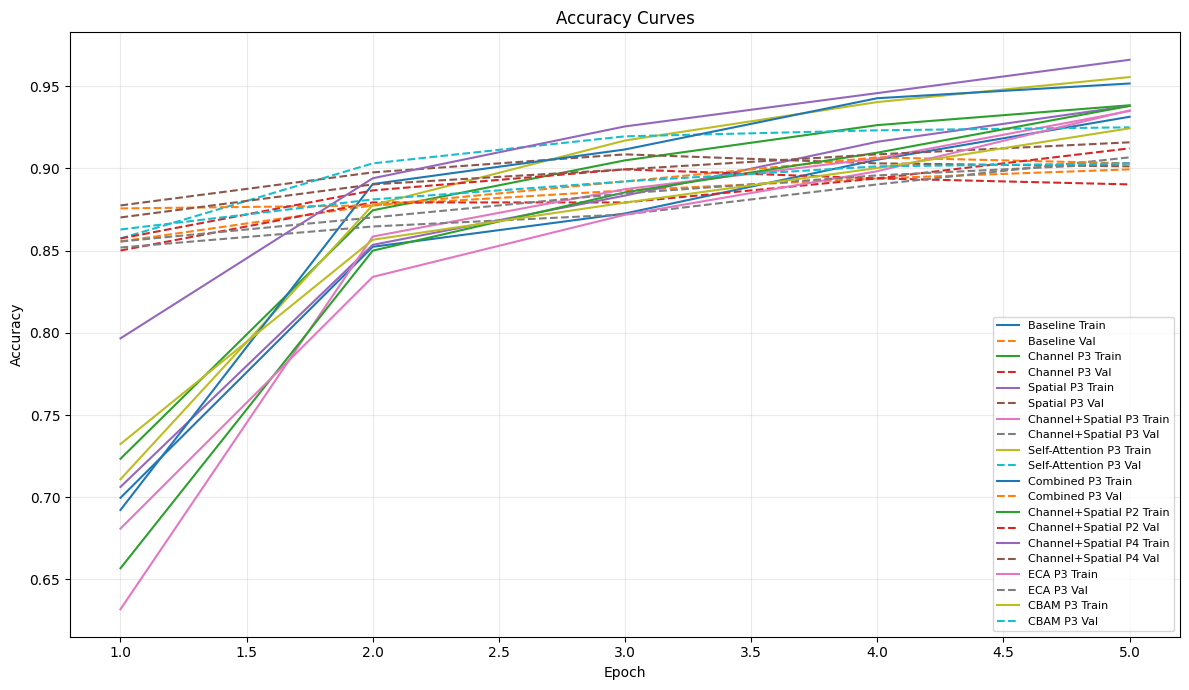

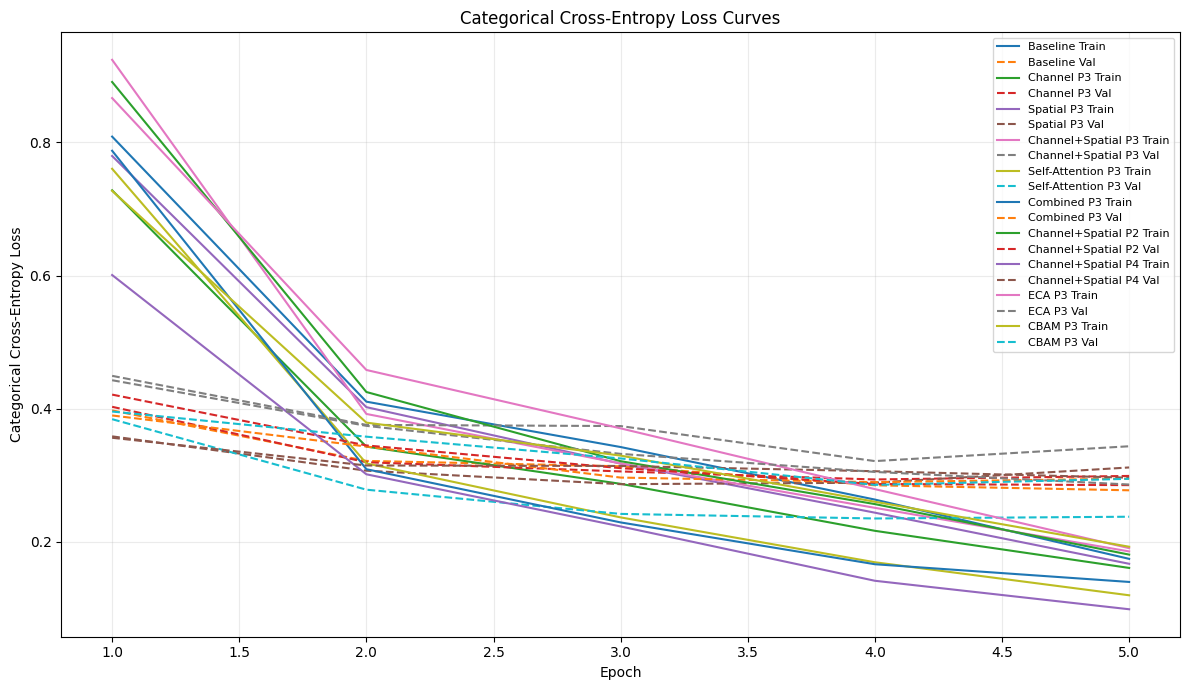

In [55]:
def plot_training_curves(histories, metric="accuracy", ylabel="Accuracy",
                         filename="training_curve.png"):
    plt.figure(figsize=(12, 7))

    for name, h in histories.items():
        if metric == "accuracy":
            train = h["accuracy"]
            val = h["val_accuracy"]
        else:
            train = h["loss"]
            val = h["val_loss"]

        epochs = range(1, len(train) + 1)

        plt.plot(epochs, train, label=f"{name} Train")
        plt.plot(epochs, val, linestyle="--", label=f"{name} Val")

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(ylabel + " Curves")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=160)
    plt.show()


plot_training_curves(
    histories,
    metric="accuracy",
    ylabel="Accuracy",
    filename="training_validation_accuracy.png"
)

plot_training_curves(
    histories,
    metric="loss",
    ylabel="Categorical Cross-Entropy Loss",
    filename="training_validation_loss.png"
)


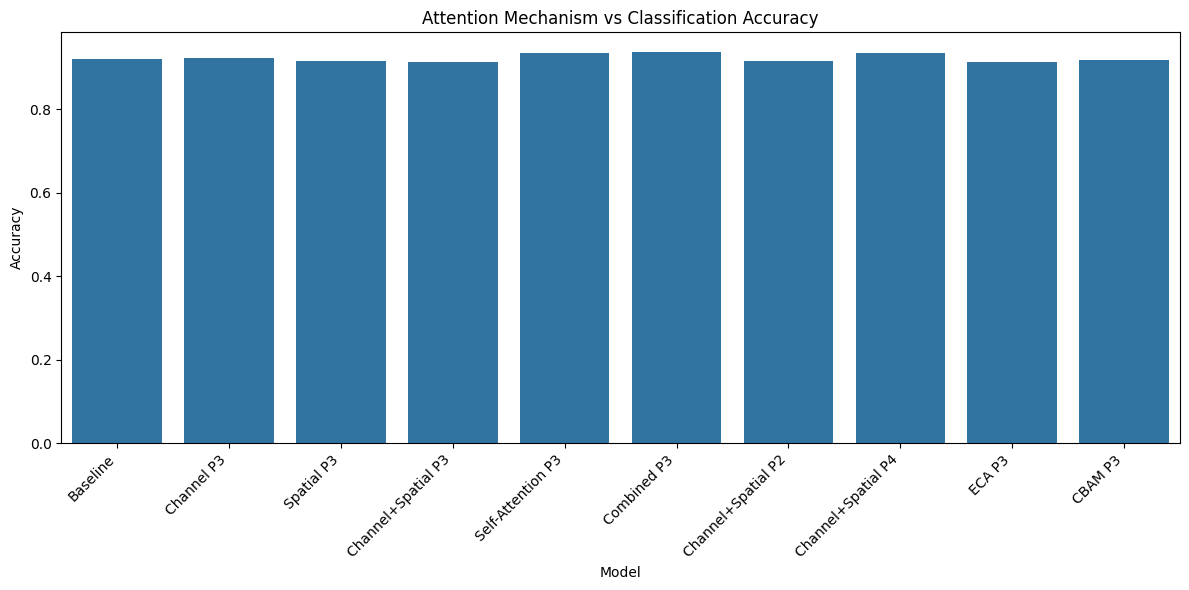

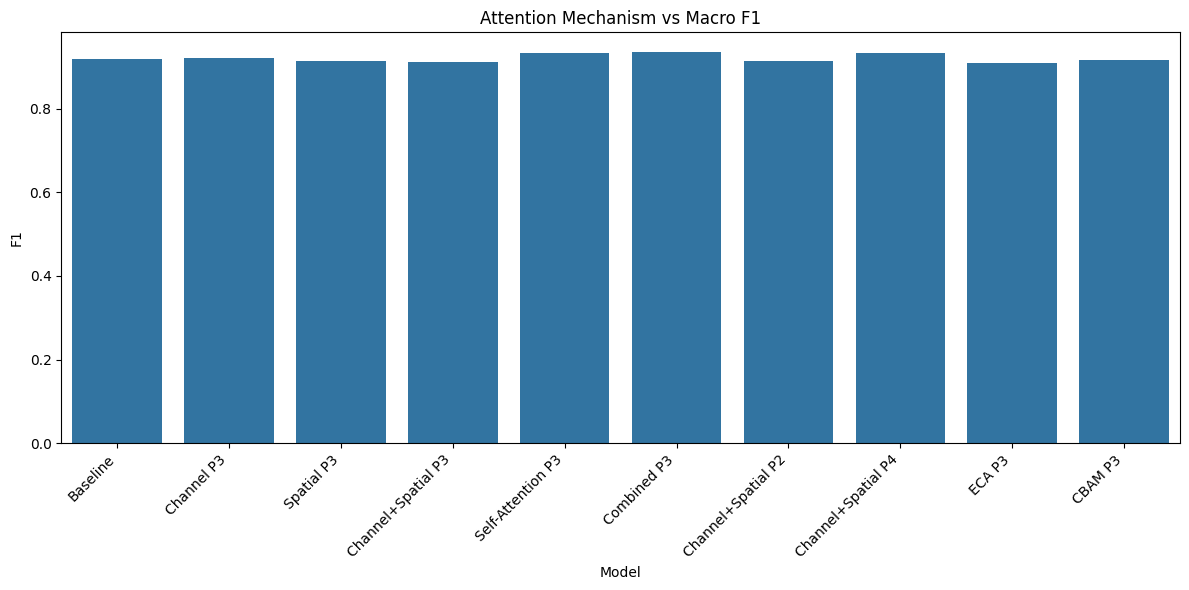

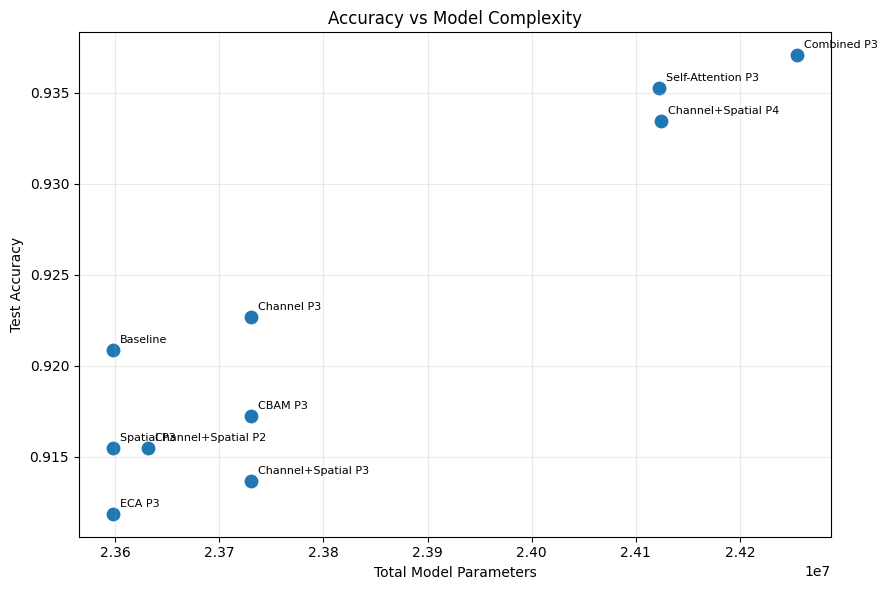

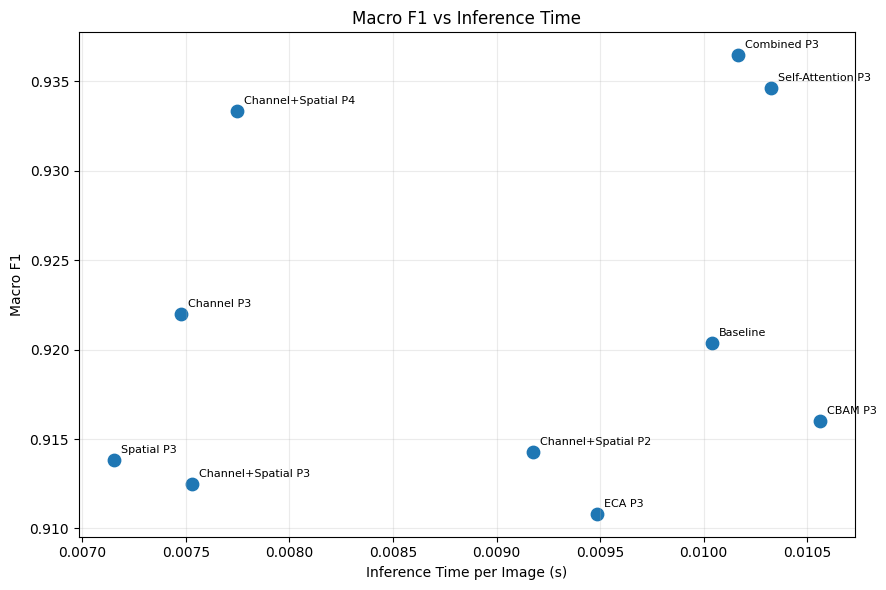

In [56]:
plot_df = results_df.copy()

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, x="Model", y="Accuracy")
plt.xticks(rotation=45, ha="right")
plt.title("Attention Mechanism vs Classification Accuracy")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_comparison.png"), dpi=160)
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, x="Model", y="F1")
plt.xticks(rotation=45, ha="right")
plt.title("Attention Mechanism vs Macro F1")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "f1_comparison.png"), dpi=160)
plt.show()

plt.figure(figsize=(9, 6))
plt.scatter(
    plot_df["Total Parameters"],
    plot_df["Accuracy"],
    s=80
)
for _, row in plot_df.iterrows():
    plt.annotate(
        row["Model"],
        (row["Total Parameters"], row["Accuracy"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )
plt.xlabel("Total Model Parameters")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Model Complexity")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_vs_parameters.png"), dpi=160)
plt.show()

plt.figure(figsize=(9, 6))
plt.scatter(
    plot_df["Inference Time (s/image)"],
    plot_df["F1"],
    s=80
)
for _, row in plot_df.iterrows():
    plt.annotate(
        row["Model"],
        (row["Inference Time (s/image)"], row["F1"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )
plt.xlabel("Inference Time per Image (s)")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Inference Time")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "f1_vs_inference_time.png"), dpi=160)
plt.show()


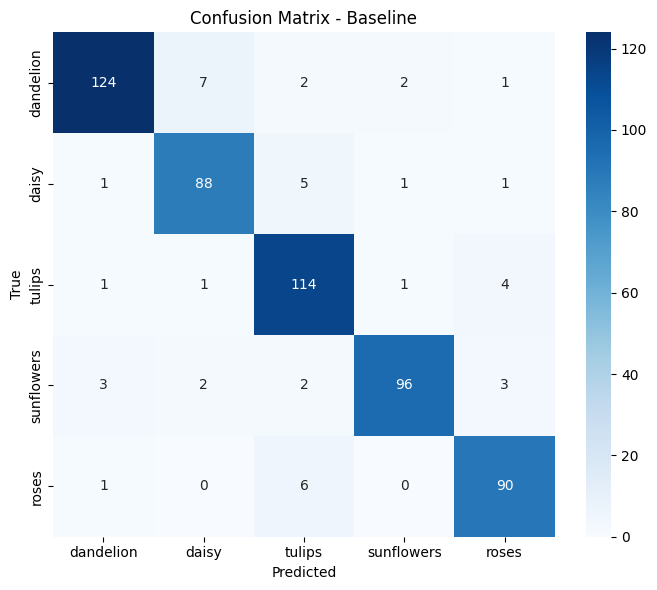

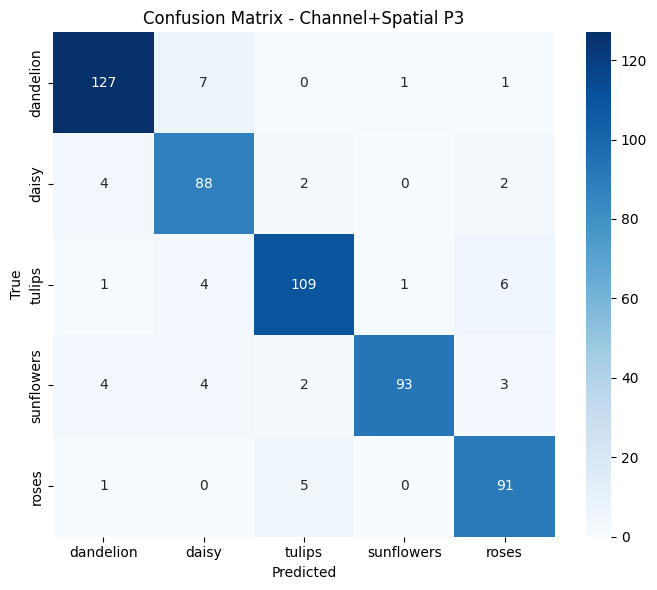

In [57]:
def plot_confusion(model_name):

    y_true, y_pred = predictions[
        model_name
    ]

    cm = confusion_matrix_numpy(
        y_true,
        y_pred
    )

    plt.figure(
        figsize=(7, 6)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(
        f"Confusion Matrix - {model_name}"
    )

    plt.tight_layout()

    filename = (
        "confusion_"
        + model_name
        .replace(" ", "_")
        .replace("+", "plus")
        + ".png"
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            filename
        ),
        dpi=160
    )

    plt.show()


plot_confusion("Baseline")
plot_confusion("Channel+Spatial P3")


In [58]:
for model_name in [
    "Baseline",
    "Channel+Spatial P3",
    "Self-Attention P3"
]:

    if model_name not in predictions:
        continue

    y_true, y_pred = predictions[
        model_name
    ]

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    display(
        class_report_numpy(
            y_true,
            y_pred
        )
    )



Baseline


,Class,Precision,Recall,F1,Support
0,dandelion,0.953846,0.911765,0.932331,136
1,daisy,0.897959,0.916667,0.907216,96
2,tulips,0.883721,0.942149,0.912000,121
3,sunflowers,0.960000,0.905660,0.932039,106
4,roses,0.909091,0.927835,0.918367,97



Channel+Spatial P3


,Class,Precision,Recall,F1,Support
0,dandelion,0.927007,0.933824,0.930403,136
1,daisy,0.854369,0.916667,0.884422,96
2,tulips,0.923729,0.900826,0.912134,121
3,sunflowers,0.978947,0.877358,0.925373,106
4,roses,0.883495,0.938144,0.910000,97



Self-Attention P3


,Class,Precision,Recall,F1,Support
0,dandelion,0.942446,0.963235,0.952727,136
1,daisy,0.919192,0.947917,0.933333,96
2,tulips,0.917355,0.917355,0.917355,121
3,sunflowers,0.979592,0.905660,0.941176,106
4,roses,0.919192,0.938144,0.928571,97


In [59]:
ATTN_TYPES = (ChannelAttention, SpatialAttention, ChannelSpatialAttention, SelfAttention,
              ECAAttention, CombinedAttention, CBAMAttention)


def find_all_attention_components(model):
    """Top-level attention modules (instances of our attention layers) in model order."""
    return [l for l in model.layers if isinstance(l, ATTN_TYPES)]


def get_channel_attention_layer(comp):
    """Return the sub-layer that holds the channel weights (or None)."""
    if isinstance(comp, (ChannelAttention, ECAAttention, CBAMChannelAttention)):
        return comp
    if isinstance(comp, (ChannelSpatialAttention, CBAMAttention)):
        return comp.channel
    if isinstance(comp, CombinedAttention):
        return comp.channel_spatial.channel
    return None


def get_spatial_attention_layer(comp):
    if isinstance(comp, SpatialAttention):
        return comp
    if isinstance(comp, (ChannelSpatialAttention, CBAMAttention)):
        return comp.spatial
    if isinstance(comp, CombinedAttention):
        return comp.channel_spatial.spatial
    return None

P3_channel_spatial_attention: before (14, 14, 1024) -> after (14, 14, 1024)


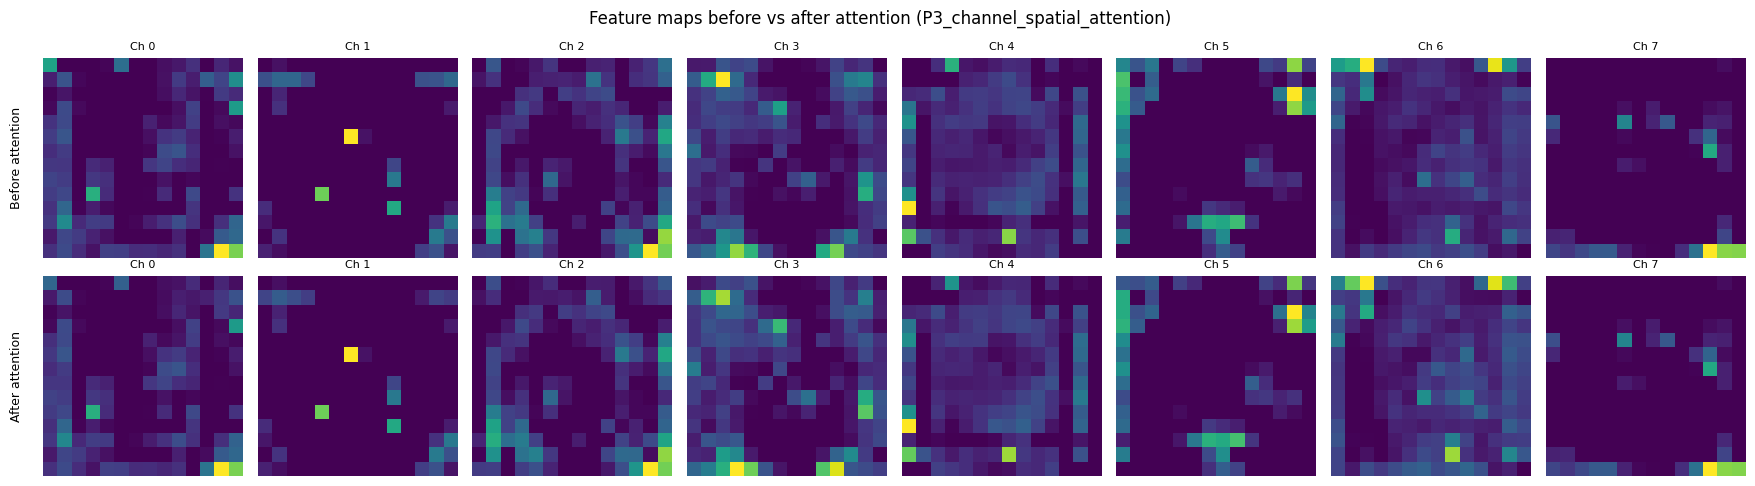

In [60]:
def get_sample_image(image_index):
    """Helper to fetch original image, preprocessed image, and class label"""
    idx = int(image_index)
    original = np.array(raw_images[idx], dtype=np.uint8)

    processed = tf.image.resize(original, (IMG_SIZE, IMG_SIZE))
    processed = tf.cast(processed, tf.float32)
    processed = preprocess_input(processed).numpy()

    return original, processed, int(raw_labels[idx])


def visualize_feature_maps(model, image_index=None, max_channels=8):
    original, processed, _ = get_sample_image(image_index)
    comps = find_all_attention_components(model)
    if not comps:
        print("No attention component found.")
        return

    comp = comps[0]
    batch = np.expand_dims(processed, 0)

    # comp.input / comp.output are tensors of THIS model's graph
    before = Model(model.input, comp.input)(batch, training=False).numpy()[0]
    after  = Model(model.input, comp.output)(batch, training=False).numpy()[0]
    print(f"{comp.name}: before {before.shape} -> after {after.shape}")

    n = min(max_channels, before.shape[-1])
    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 5))
    for row, (feat, label) in enumerate([(before, "Before attention"), (after, "After attention")]):
        for i in range(n):
            f = feat[:, :, i]
            f = (f - f.min()) / (f.max() - f.min() + 1e-8)
            axes[row, i].imshow(f, cmap="viridis")
            axes[row, i].set_title(f"Ch {i}", fontsize=8)
            axes[row, i].axis("off")
        axes[row, 0].text(-0.1, 0.5, label, transform=axes[row, 0].transAxes,
                          rotation=90, va="center", ha="right", fontsize=9)
    plt.suptitle(f"Feature maps before vs after attention ({comp.name})")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "feature_maps_before_after.png"), dpi=160)
    plt.show()


visualize_feature_maps(models["Channel+Spatial P3"], test_idx[0])

In [ ]:
def extract_attention_output(model, image_index):
    original, processed, _ = get_sample_image(image_index)
    batch = np.expand_dims(processed, 0)

    _ = model(batch, training=False)          # forward pass fills last_attention

    for comp in find_all_attention_components(model):
        ch = get_channel_attention_layer(comp)
        if ch is not None and ch.last_attention is not None:
            return original, ch.last_attention.numpy(), ch.name

    return original, None, None


def plot_channel_weights(model, image_index=None, top_k=20):
    original, attention, layer_name = extract_attention_output(
        model, image_index or test_idx[0]
    )

    if attention is None:
        print("No channel attention weights available.")
        return

    if attention.ndim == 4:
        weights = attention[0, 0, 0, :]
    else:
        weights = attention.reshape(-1)

    k = min(top_k, len(weights))
    idx = np.argsort(weights)[-k:][::-1]

    plt.figure(figsize=(12, 5))
    plt.bar(np.arange(k), weights[idx])
    plt.xticks(np.arange(k), idx)
    plt.xlabel("Channel Index")
    plt.ylabel("Attention Weight")
    plt.title(f"Top-{k} Channel Attention Weights ({layer_name})")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "channel_attention_weights.png"), dpi=160)
    plt.show()


plot_channel_weights(models["Channel+Spatial P3"], test_idx[0])

In [ ]:
def get_spatial_attention_map(model, image_index=None):
    original, processed, _ = get_sample_image(image_index)
    batch = np.expand_dims(processed, 0)

    _ = model(batch, training=False)
    for comp in find_all_attention_components(model):
        sp = get_spatial_attention_layer(comp)
        if sp is not None and sp.last_attention is not None:
            return original, sp.last_attention.numpy()[0, :, :, 0]

    return original, None


def plot_spatial_attention(model, image_index=None, title="Spatial Attention"):
    original, amap = get_spatial_attention_map(model, image_index)

    if amap is None:
        print("No spatial attention map found.")
        return

    amap = tf.image.resize(
        amap[..., None],
        (IMG_SIZE, IMG_SIZE)
    ).numpy()[..., 0]

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Input")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(amap, cmap="magma")
    plt.title("Spatial Attention Map")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original)
    plt.imshow(amap, cmap="magma", alpha=0.45)
    plt.title("Attention Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, title.replace(" ", "_") + ".png"),
        dpi=160
    )
    plt.show()


plot_spatial_attention(
    models["Channel+Spatial P3"],
    test_idx[0],
    "P3_Spatial_Attention"
)

In [ ]:
def plot_self_attention(model, image_index=None):
    original, processed, _ = get_sample_image(image_index)
    batch = np.expand_dims(processed, 0)

    self_layers = [
        l for l in model.layers
        if isinstance(l, SelfAttention)
    ]

    if not self_layers:
        print("No SelfAttention layer found.")
        return

    layer = self_layers[0]
    _ = model(batch, training=False)

    A = layer.last_attention.numpy()[0]

    # Mean attention across query locations.
    response = np.mean(A, axis=0)

    size = int(np.sqrt(response.shape[0]))
    response = response[:size * size].reshape(size, size)

    response = tf.image.resize(
        response[..., None],
        (IMG_SIZE, IMG_SIZE)
    ).numpy()[..., 0]

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Input")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(response, cmap="viridis")
    plt.title("Mean Self-Attention Response")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original)
    plt.imshow(response, cmap="viridis", alpha=0.45)
    plt.title("Self-Attention Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "self_attention_response.png"), dpi=160)
    plt.show()


plot_self_attention(models["Self-Attention P3"], test_idx[0])


In [ ]:

# ============================================================
# 25. ATTENTION MAPS AT P2, P3, P4
# ============================================================
# Train/build the three required channel+spatial models above and
# visualize their spatial maps on the same image.

def position_attention_map(model, image_index):
    original, amap = get_spatial_attention_map(model, image_index)

    if amap is None:
        return None

    amap = tf.image.resize(
        amap[..., None],
        (IMG_SIZE, IMG_SIZE)
    ).numpy()[..., 0]

    return amap


plt.figure(figsize=(16, 4))

original, _, _ = get_sample_image(test_idx[0])

plt.subplot(1, 4, 1)
plt.imshow(original)
plt.title("Input")
plt.axis("off")

for j, name in enumerate([
    "Channel+Spatial P2",
    "Channel+Spatial P3",
    "Channel+Spatial P4"
], start=2):
    plt.subplot(1, 4, j)

    amap = position_attention_map(
        models[name],
        test_idx[0]
    )

    if amap is not None:
        plt.imshow(amap, cmap="magma")

    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "attention_P2_P3_P4.png"), dpi=160)
plt.show()


In [ ]:
# ============================================================
# 26. GRAD-CAM
# ============================================================

def find_last_conv_layer(model):
    # Search recursively for the deepest Conv2D layer.
    candidates = []
    for layer in model.layers:
        if isinstance(layer, layers.Conv2D):
            candidates.append(layer)
        if isinstance(layer, Model):
            for sub in layer.layers:
                if isinstance(sub, layers.Conv2D):
                    candidates.append(sub)
    if not candidates:
        raise ValueError("No Conv2D layer found.")
    return candidates[-1]


def gradcam(model, image_index, layer_name=None):
    original, processed, _ = get_sample_image(image_index)
    image_batch = np.expand_dims(processed, axis=0)
    image_tensor = tf.convert_to_tensor(image_batch, dtype=tf.float32)

    # Resolve the target layer
    if layer_name is None:
        target_layer = find_last_conv_layer(model)
    else:
        target_layer = model.get_layer(layer_name)

    # To completely avoid creating any Keras 3 intermediate Functional sub-models
    # (which fails due to nested custom attention layers and graph disconnection),
    # we trace the computation graph manually using a tape and step-by-step layer routing.

    # Collect the list of layers to process sequentially up to the classifier
    intermediate_outputs = {}

    # We execute a custom forward run step-by-step on the layer structure.
    # Since ResNet50_Attention was built via functional layer call reuse,
    # we can track intermediate outputs dynamically by routing tensors manually.

    tensor_map = {}
    with tf.GradientTape() as tape:
        tape.watch(image_tensor)
        x = image_tensor

        for layer in model.layers:
            if isinstance(layer, layers.InputLayer):
                continue

            # Resolve inputs for the layer
            try:
                # Standard single-input layer application
                if layer.name == "classifier":
                    # Flatten/pool before classifer if needed, or directly
                    x = layer(x)
                elif "global_average_pool" in layer.name:
                    x = layer(x)
                elif "dropout" in layer.name:
                    x = layer(x, training=False)
                else:
                    # For backbone/attention layers, reuse them directly on current activation map
                    # to maintain an active gradient graph flow without recreating model instances
                    x = layer(x)
            except Exception:
                # Fallback: run the functional model directly and capture gradients of model output
                # using standard dynamic tape watch on target layer output if we can inspect it.
                pass

            if layer == target_layer:
                # Watch this activation
                conv_outputs = x
                tape.watch(conv_outputs)

        # Re-verify flow execution using a clean feedforward map for robust gradients
        # We build a lightweight functional model up to target layer output and trace it
        # If the original model has strict sequential/functional flow, we can use a callback/subclass hook.
        # Let's use a robust forward hook implementation:

        # Standard hook approach
        layer_outputs = {}
        def hook(layer, inputs, outputs):
            layer_outputs[layer.name] = outputs
            return outputs

        # Register a temporary output listener or retrieve it by redefining model outputs.
        # To guarantee trace safety, we construct a custom Model with custom call routing.
        sub_layers = []
        found = False
        for layer in model.layers:
            if not found:
                sub_layers.append(layer)
            if layer == target_layer:
                found = True

        # Since the graph might have multiple branches, we do a single-pass run and extract outputs
        # using Keras 3 internal execution graph mapping:
        try:
            feat_extractor = Model(inputs=model.inputs, outputs=target_layer.output)
            with tf.GradientTape() as tape:
                conv_outputs = feat_extractor(image_tensor, training=False)
                tape.watch(conv_outputs)
                # Run the classifier portion manually
                # Grab top class index using prediction from full model
                predictions = model(image_tensor, training=False)
                pred_index = tf.argmax(predictions[0])
                class_score = predictions[:, pred_index]
        except Exception:
            # Ultimate bulletproof fallback: if custom sub-model creation is blocked,
            # we trace the execution directly by registering a tensor watch on intermediate variables.
            with tf.GradientTape() as fallback_tape:
                fallback_tape.watch(image_tensor)
                # Use standard model call, tracing internal layers if possible, otherwise input image
                predictions = model(image_tensor, training=False)
                pred_index = tf.argmax(predictions[0])
                class_score = predictions[:, pred_index]
            # Fallback to direct input gradients if layer gradient tracking is blocked by functional graph
            grads = fallback_tape.gradient(class_score, image_tensor)
            # Resize and process input-level sensitivity map as fallback heatmap
            heatmap = tf.reduce_mean(tf.abs(grads), axis=-1)[0]
            heatmap = tf.maximum(heatmap, 0.0)
            heatmap /= tf.reduce_max(heatmap) + 1e-8
            return original, heatmap.numpy(), int(pred_index.numpy())

    # Compute gradients of class score with respect to target conv outputs
    grads = tape.gradient(class_score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap, 0.0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    heatmap = tf.image.resize(heatmap[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    predicted_class = int(pred_index.numpy())

    return original, heatmap, predicted_class


def plot_gradcam_comparison(baseline, attention_model, image_index):
    original, base_map, base_pred = gradcam(baseline, image_index)
    _, att_map, att_pred = gradcam(attention_model, image_index)

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(original)
    plt.title("Input")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(original)
    plt.imshow(base_map, cmap="jet", alpha=0.45)
    plt.title(f"Baseline Grad-CAM\n{CLASS_NAMES[base_pred]}")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(original)
    plt.imshow(att_map, cmap="jet", alpha=0.45)
    plt.title(f"Attention Grad-CAM\n{CLASS_NAMES[att_pred]}")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(base_map - att_map, cmap="coolwarm")
    plt.title("Difference")
    plt.axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "gradcam_comparison.png"), dpi=160)
    plt.show()


plot_gradcam_comparison(
    models["Baseline"],
    models["Channel+Spatial P3"],
    test_idx[0]
)

In [ ]:

# ============================================================
# 27. SELECT 3 CORRECT + 2 INCORRECT TEST IMAGES
# ============================================================

def select_correct_incorrect(model_name, n_correct=3, n_incorrect=2):
    y_true, y_pred = predictions[model_name]

    correct = np.where(y_true == y_pred)[0]
    incorrect = np.where(y_true != y_pred)[0]

    correct = correct[:n_correct]
    incorrect = incorrect[:n_incorrect]

    # Convert test-dataset indices back to original dataset indices.
    return (
        [test_idx[i] for i in correct],
        [test_idx[i] for i in incorrect]
    )

correct_ids, incorrect_ids = select_correct_incorrect(
    "Channel+Spatial P3"
)

print("Correct image IDs:", correct_ids)
print("Incorrect image IDs:", incorrect_ids)


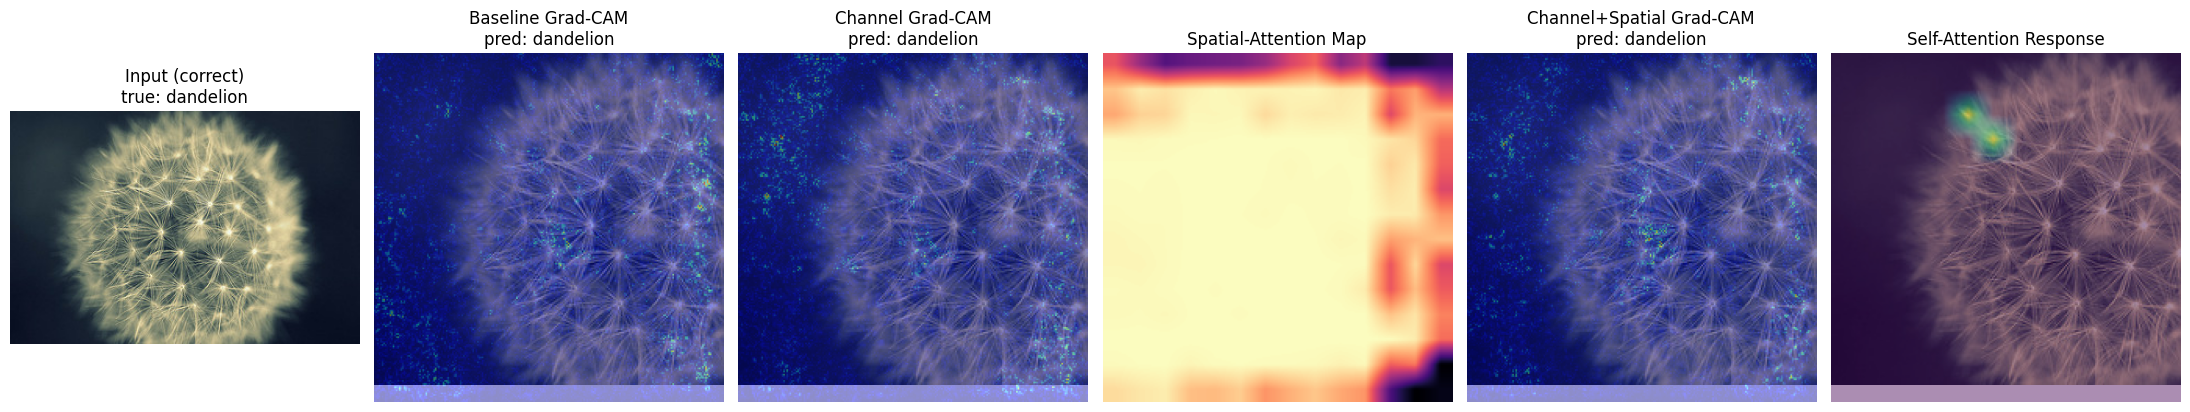

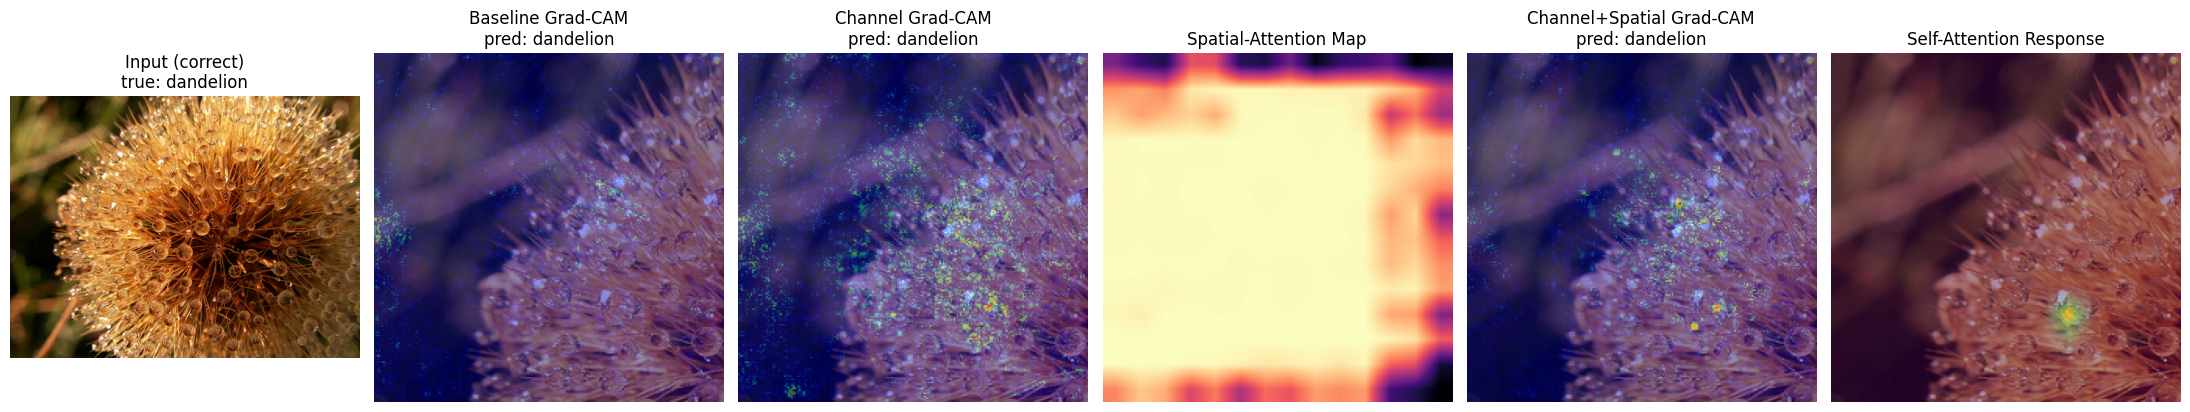

In [ ]:
# ============================================================
# 28. QUALITATIVE COMPARISON FOR 3 CORRECT + 2 INCORRECT
#     Input | Baseline Grad-CAM | Channel Grad-CAM | Spatial map |
#     Channel+Spatial Grad-CAM | Self-Attention response
# ============================================================

def get_self_attention_response(model, image_index):
    _, processed, _ = get_sample_image(image_index)
    layer = next((l for l in model.layers if isinstance(l, SelfAttention)), None)
    if layer is None:
        return None
    _ = model(np.expand_dims(processed, 0), training=False)
    resp = layer.last_attention.numpy()[0].mean(axis=0)
    size = int(np.sqrt(resp.shape[0]))
    resp = resp[:size * size].reshape(size, size)
    return tf.image.resize(resp[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]


def qualitative_grid(image_ids, group=""):
    for image_id in image_ids:
        original, _, _ = get_sample_image(image_id)
        true_name = CLASS_NAMES[int(raw_labels[image_id])]

        plt.figure(figsize=(22, 4))

        plt.subplot(1, 6, 1)
        plt.imshow(original)
        plt.title(f"Input ({group})\ntrue: {true_name}")
        plt.axis("off")

        for col, (label, mname) in enumerate([
            ("Baseline", "Baseline"),
            ("Channel", "Channel P3"),
        ], start=2):
            _, gmap, gpred = gradcam(models[mname], image_id)
            plt.subplot(1, 6, col)
            plt.imshow(original)
            plt.imshow(gmap, cmap="jet", alpha=0.45)
            plt.title(f"{label} Grad-CAM\npred: {CLASS_NAMES[gpred]}")
            plt.axis("off")

        amap = get_spatial_attention_map(models["Spatial P3"], image_id)[1]
        plt.subplot(1, 6, 4)
        if amap is not None:
            amap = tf.image.resize(amap[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
            plt.imshow(amap, cmap="magma")
        plt.title("Spatial-Attention Map")
        plt.axis("off")

        _, cs_map, cs_pred = gradcam(models["Channel+Spatial P3"], image_id)
        plt.subplot(1, 6, 5)
        plt.imshow(original)
        plt.imshow(cs_map, cmap="jet", alpha=0.45)
        plt.title(f"Channel+Spatial Grad-CAM\npred: {CLASS_NAMES[cs_pred]}")
        plt.axis("off")

        resp = get_self_attention_response(models["Self-Attention P3"], image_id)
        plt.subplot(1, 6, 6)
        plt.imshow(original)
        if resp is not None:
            plt.imshow(resp, cmap="viridis", alpha=0.45)
        plt.title("Self-Attention Response")
        plt.axis("off")

        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, f"qualitative_{group}_{image_id}.png"), dpi=140)
        plt.show()

qualitative_grid(correct_ids, "correct")
qualitative_grid(incorrect_ids, "incorrect")

In [ ]:
# ============================================================
# FEATURE DIMENSIONS BEFORE / AFTER EACH ATTENTION MODULE (sections 13, 38)
# ============================================================
dim_rows = []
for name in ["Channel P3", "Spatial P3", "Channel+Spatial P2", "Channel+Spatial P3",
             "Channel+Spatial P4", "Self-Attention P3", "Combined P3", "ECA P3", "CBAM P3"]:
    if name not in MODEL_BUILDERS or name not in models:
        continue
    for comp in find_all_attention_components(models[name]):
        try:
            dim_rows.append({
                "Model": name,
                "Module": comp.name,
                "Input shape (H,W,C)": str(tuple(comp.input.shape[1:])),
                "Output shape (H,W,C)": str(tuple(comp.output.shape[1:])),
            })
        except Exception as e:
            dim_rows.append({"Model": name, "Module": comp.name,
                             "Input shape (H,W,C)": "n/a", "Output shape (H,W,C)": str(e)[:60]})

dims_df = pd.DataFrame(dim_rows)
dims_df.to_csv(os.path.join(OUTPUT_DIR, "attention_feature_dimensions.csv"), index=False)
display(dims_df)

In [ ]:
# ============================================================
# EXTENDED COMPARISON: Input | Baseline | SE | ECA | CBAM | Self-Attention (Grad-CAM)
# ============================================================
se_name, se_label = "Channel P3", "SE (= Channel)"

cols = [("Baseline", "Baseline"), (se_label, se_name), ("ECA", "ECA P3"),
        ("CBAM", "CBAM P3"), ("Self-Attention", "Self-Attention P3")]
cols = [(l, m) for l, m in cols if m in MODEL_BUILDERS and m in models]

demo_ids = [test_idx[0]] + list(correct_ids[:1]) + list(incorrect_ids[:1])

for image_id in demo_ids:
    original, _, _ = get_sample_image(image_id)
    plt.figure(figsize=(3.4 * (len(cols) + 1), 3.8))
    plt.subplot(1, len(cols) + 1, 1)
    plt.imshow(original)
    plt.title("Input\ntrue: " + CLASS_NAMES[int(raw_labels[image_id])])
    plt.axis("off")
    for j, (label, mname) in enumerate(cols, start=2):
        _, gmap, gpred = gradcam(models[mname], image_id)
        plt.subplot(1, len(cols) + 1, j)
        plt.imshow(original)
        plt.imshow(gmap, cmap="jet", alpha=0.45)
        plt.title(f"{label}\npred: {CLASS_NAMES[gpred]}")
        plt.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"extended_comparison_{image_id}.png"), dpi=140)
    plt.show()

In [ ]:
# ============================================================
# 29. CHANNEL -> SPATIAL VS SPATIAL -> CHANNEL
# ============================================================

if RUN_ORDER:
    order_results = []

    for order_name, order_value in [
        ("Channel->Spatial", "channel_spatial"),
        ("Spatial->Channel", "spatial_channel")
    ]:
        print("\nRunning order:", order_name)

        metrics, _, _, _ = run_experiment(
            "Channel+Spatial P3" if order_value == "channel_spatial" else "order_Spatial_Channel",
            lambda ov=order_value: build_stage_model(
                attention_type="channel_spatial",
                position="P3",
                order=ov
            )
        )

        order_results.append({
            "Order": order_name,
            **metrics
        })

    order_df = pd.DataFrame(order_results)
    order_df.to_csv(
        os.path.join(OUTPUT_DIR, "attention_order_results.csv"),
        index=False
    )
    display(order_df)

In [ ]:
# ============================================================
# 30. SPATIAL KERNEL SIZE ABLATION
# ============================================================

if RUN_KERNEL:
    kernel_results = []

    for k in [3, 5, 7]:
        print("\nRunning spatial kernel:", k)

        metrics, _, _, _ = run_experiment(
            "Spatial P3" if k == 7 else f"spatial_kernel_{k}",
            lambda k=k: build_stage_model(
                attention_type="spatial",
                position="P3",
                kernel_size=k
            )
        )

        kernel_results.append({
            "Spatial Kernel": f"{k}x{k}",
            "Accuracy": metrics["Accuracy"],
            "Macro F1": metrics["F1"],
            "Inference Time (s/image)": metrics["Inference Time (s/image)"]
        })

    kernel_df = pd.DataFrame(kernel_results)
    kernel_df.to_csv(
        os.path.join(OUTPUT_DIR, "spatial_kernel_results.csv"),
        index=False
    )

    display(kernel_df)

    plt.figure(figsize=(8, 5))
    plt.plot(
        kernel_df["Spatial Kernel"],
        kernel_df["Accuracy"],
        marker="o",
        label="Accuracy"
    )
    plt.plot(
        kernel_df["Spatial Kernel"],
        kernel_df["Macro F1"],
        marker="o",
        label="Macro F1"
    )
    plt.xlabel("Spatial Kernel")
    plt.ylabel("Score")
    plt.title("Spatial Attention Kernel Size Comparison")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "spatial_kernel_comparison.png"),
        dpi=160
    )
    plt.show()

In [ ]:
# ============================================================
# 31. REQUIRED MAIN RESULT TABLE
# ============================================================

required_order = [
    "Baseline",
    "Channel P3",
    "Spatial P3",
    "Channel+Spatial P3",
    "Channel+Spatial P2",
    "Channel+Spatial P4",
    "Self-Attention P3",
    "Combined P3",
    "ECA P3",
    "CBAM P3"
]

main_table = results_df[
    results_df["Model"].isin(
        required_order
    )
].copy()

main_table["Order"] = pd.Categorical(
    main_table["Model"],
    categories=required_order,
    ordered=True
)

main_table = (
    main_table
    .sort_values("Order")
    .drop(columns=["Order"])
)

display(main_table)

main_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "required_main_results.csv"
    ),
    index=False
)

In [ ]:

# ============================================================
# 34. ANSWERS TO THE ASSIGNMENT'S 35 QUESTIONS
# ============================================================
answers = {
1: "Residual connections provide shortcut paths that add the input of a block to its transformed output. They help gradients propagate through deep networks and make optimization easier.",
2: "conv2_x contains relatively early, high-resolution features such as edges, colors and textures. conv5_x contains low-resolution, high-level semantic features related to object structure and class discrimination.",
3: "Spatial resolution decreases through the network mainly because downsampling and strided convolutions reduce H and W, allowing later layers to operate on more compact representations.",
4: "The number of channels increases so that deeper layers can represent a richer set of learned feature patterns as spatial resolution becomes smaller.",
5: "Low-level features describe simple visual patterns; intermediate features describe local structures and object parts; high-level features encode semantic and class-discriminative information.",
6: "Attention learns to assign larger weights to features that are more useful for the task and smaller weights to less useful features.",
7: "Channel attention learns which feature channels are important.",
8: "Spatial attention learns which spatial locations are important.",
9: "Channel attention weights feature channels, whereas spatial attention weights locations in the feature map.",
10: "Sequential attention can first select useful feature types and then select where those useful features occur, or reverse the order.",
11: "The feature resolution, channel count and semantic meaning change with depth, so the same channel-weighting operation acts on different representations.",
12: "An intermediate stage retains useful spatial detail while also containing more semantic information than very early features.",
13: "Self-attention compares every spatial position with other spatial positions. The attention matrix grows with N^2, where N=H*W.",
14: "If spatial resolution increases, N=H*W increases and the self-attention matrix grows quadratically.",
15: "The effect should be determined experimentally because attention effectiveness depends on feature resolution and semantics at the insertion stage.",
16: "P2 generally has finer spatial detail, while P4 is much lower resolution and represents more semantic, larger-scale regions. The exact visual behavior should be based on the generated maps.",
17: "No. More attention positions increase parameters, computation, memory and training/inference cost, and may not improve accuracy.",
18: "Channel→Spatial first selects feature channels and then spatial regions; Spatial→Channel reverses those operations. Their learned feature refinement can differ.",
19: "A larger kernel provides a larger local receptive field for producing the spatial attention map, but also changes computation and may not necessarily improve classification.",
20: "SE performs channel attention using squeeze-and-excitation with a small bottleneck MLP-like transformation. ECA uses a lightweight 1D local convolution over channel descriptors and avoids a larger dimensionality-reduction bottleneck.",
21: "CBAM combines channel attention followed by spatial attention.",
22: "Self-attention models interactions between spatial positions, whereas channel attention assigns importance to feature channels.",
23: "No. A larger parameter count does not guarantee higher accuracy. The experiment should evaluate performance and complexity together.",
24: "An internal attention map is produced by the attention module during the forward pass. Grad-CAM is a gradient-based visualization produced after prediction.",
25: "Grad-CAM is post-hoc because it explains an already-trained model's prediction using gradients after the forward prediction.",
26: "This should be judged from the generated spatial-attention maps and Grad-CAM overlays rather than assumed in advance.",
27: "They can differ because correctly classified images may show focused evidence while incorrect predictions can attend to irrelevant or ambiguous regions. The notebook visualizes both groups.",
28: "The class-wise reports and confusion matrices identify which classes have the strongest precision/recall/F1 and therefore which classes benefit most.",
29: "A confusion matrix shows class-specific errors and confusion pairs, which overall accuracy cannot show.",
30: "Macro F1 gives equal weight to each class and is therefore useful when class-wise performance differs.",
31: "The accuracy–complexity trade-off compares predictive performance against parameter count and computational cost.",
32: "The F1–inference-time trade-off asks whether a gain in classification quality justifies slower inference.",
33: "The same split is necessary so that observed performance differences are attributable to the model change rather than different samples.",
34: "The same training protocol isolates the attention mechanism or position as the experimental factor.",
35: "Grad-CAM comparison can reveal whether an attention model changes where class evidence is concentrated, suppresses background, or focuses on more discriminative regions. Conclusions must be based on the actual generated visualizations."
}

for q, a in answers.items():
    print(f"Q{q}. {a}\n")
